<a href="https://colab.research.google.com/github/SaiSriHarsha2006/Labmatrix-1/blob/main/zomato.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Mount Google Drive

Run the cell below to mount your Google Drive. You will be prompted to give Colab permission to access your files.

Zomato  Data<n>

https://drive.google.com/file/d/1YEpeBRL3HwvzkhWzXZt4VB_7eH8Wf2O8/view?usp=drive_link<n>

Zomato Meta Data

https://drive.google.com/file/d/1493xGT8t66Wr3_cRxY_OvW_KNYNSNFrt/view?usp=drive_link

In [1]:
import pandas as pd
import numpy as np
import requests
import io

# Direct download link for Zomato Restaurant reviews.csv
url_reviews = 'https://docs.google.com/uc?export=download&id=1YEpeBRL3HwvzkhWzXZt4VB_7eH8Wf2O8'

print("Downloading Zomato Restaurant reviews...")
response = requests.get(url_reviews)

# Load into Pandas
df = pd.read_csv(io.BytesIO(response.content))
print(f"Successfully loaded dataset with shape: {df.shape}")
display(df.head())

Successfully loaded dataset with shape: (10000, 7)


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
dfc=df.copy()
dfc.drop_duplicates(inplace=True)
dfc.dropna(subset=['Review','Rating'],inplace=False)
# Rating to numeric
dfc['Rating']=pd.to_numeric(dfc['Rating'],errors='coerce')
dfc.dropna(subset=['Rating'],inplace=True)
dfc['Reviewer_Reviews'] = (
    dfc['Metadata']
    .str.extract(r'(\d+)\s*Review', expand=False)
    .fillna(0)
    .astype(int)
)
dfc['Reviewer_Followers'] = (
    dfc['Metadata']
    .str.extract(r'(\d+)\s*Follower', expand=False)
    .fillna(0)
    .astype(int)
)

# 6. Convert 'Time' to datetime format
dfc['Time'] = pd.to_datetime(dfc['Time'], errors='coerce')

# 7. Strip extra whitespace and clean newlines in text columns
dfc['Review'] = dfc['Review'].str.strip().str.replace(r'\s+', ' ', regex=True)
dfc['Restaurant'] = dfc['Restaurant'].str.strip()

# 8. Reset index and inspect the cleaned dataset
dfc.reset_index(drop=True, inplace=True)
print(f"Original shape: {df.shape} -> Cleaned shape: {dfc.shape}")
display(dfc.info())
display(dfc.head())

Original shape: (10000, 7) -> Cleaned shape: (9961, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9961 entries, 0 to 9960
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Restaurant          9961 non-null   object        
 1   Reviewer            9961 non-null   object        
 2   Review              9954 non-null   object        
 3   Rating              9961 non-null   float64       
 4   Metadata            9961 non-null   object        
 5   Time                9961 non-null   datetime64[ns]
 6   Pictures            9961 non-null   int64         
 7   Reviewer_Reviews    9961 non-null   int64         
 8   Reviewer_Followers  9961 non-null   int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(4)
memory usage: 700.5+ KB


None

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Reviewer_Reviews,Reviewer_Followers
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5.0,"1 Review , 2 Followers",2019-05-25 15:54:00,0,1,2
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5.0,"3 Reviews , 2 Followers",2019-05-25 14:20:00,0,3,2
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5.0,"2 Reviews , 3 Followers",2019-05-24 22:54:00,0,2,3
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5.0,"1 Review , 1 Follower",2019-05-24 22:11:00,0,1,1
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5.0,"3 Reviews , 2 Followers",2019-05-24 21:37:00,0,3,2


In [3]:
dfs=dfc.copy()
dfs

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Reviewer_Reviews,Reviewer_Followers
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5.0,"1 Review , 2 Followers",2019-05-25 15:54:00,0,1,2
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5.0,"3 Reviews , 2 Followers",2019-05-25 14:20:00,0,3,2
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5.0,"2 Reviews , 3 Followers",2019-05-24 22:54:00,0,2,3
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5.0,"1 Review , 1 Follower",2019-05-24 22:11:00,0,1,1
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5.0,"3 Reviews , 2 Followers",2019-05-24 21:37:00,0,3,2
...,...,...,...,...,...,...,...,...,...
9956,Chinese Pavilion,Abhishek Mahajan,Madhumathi Mahajan Well to start with nice cou...,3.0,"53 Reviews , 54 Followers",2016-06-05 00:08:00,0,53,54
9957,Chinese Pavilion,Sharad Agrawal,This place has never disappointed us.. The foo...,4.5,"2 Reviews , 53 Followers",2016-06-04 22:01:00,0,2,53
9958,Chinese Pavilion,Ramandeep,"Bad rating is mainly because of ""Chicken Bone ...",1.5,"65 Reviews , 423 Followers",2016-06-03 10:37:00,3,65,423
9959,Chinese Pavilion,Nayana Shanbhag,I personally love and prefer Chinese Food. Had...,4.0,"13 Reviews , 144 Followers",2016-05-31 17:22:00,0,13,144


**Perform EDA**

--- Statistical Summary ---


,Rating,Time,Pictures,Reviewer_Reviews,Reviewer_Followers
count,9961.000000,9961,9961.000000,9961.000000,9961.000000
mean,3.601044,2018-11-29 10:00:59.771107072,0.751431,23.946090,163.008433
min,1.000000,2016-05-31 16:41:00,0.000000,0.000000,0.000000
25%,3.000000,2018-08-11 22:12:00,0.000000,1.000000,1.000000
50%,4.000000,2018-12-23 21:18:00,0.000000,4.000000,7.000000
75%,5.000000,2019-03-31 18:15:00,0.000000,22.000000,63.000000
max,5.000000,2019-05-25 20:23:00,64.000000,1031.000000,13410.000000
std,1.483461,NaN,2.574991,50.592184,619.979721


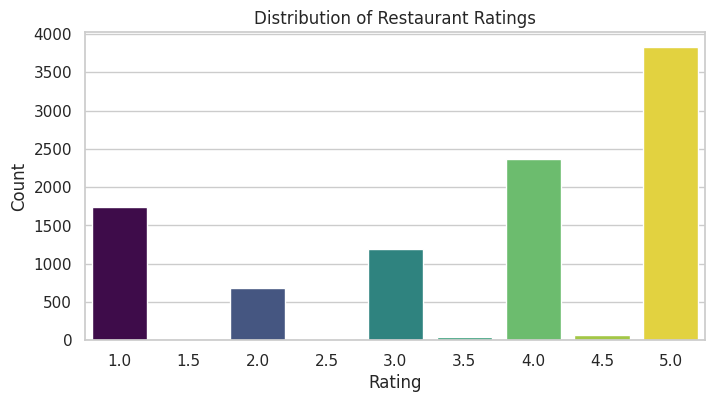

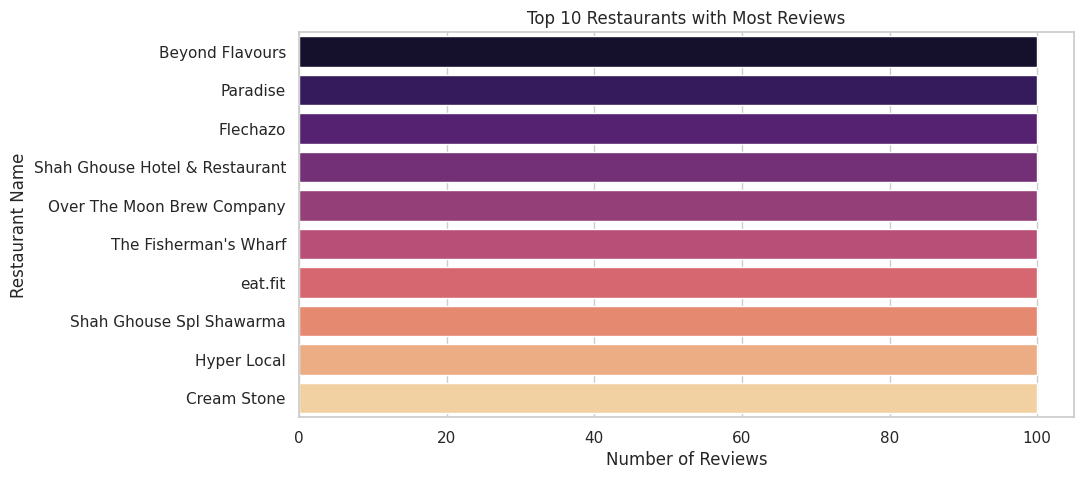

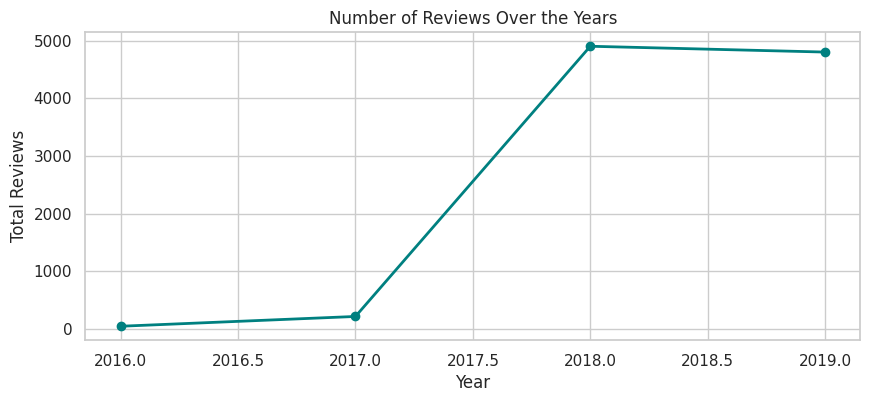

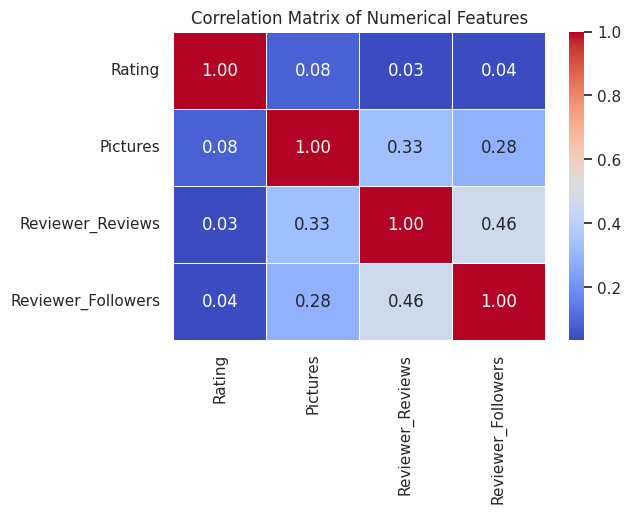

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# 1. Statistical Summary of Numerical Features
print("--- Statistical Summary ---")
display(dfs.describe())

# 2. Distribution of Ratings
plt.figure(figsize=(8, 4))
sns.countplot(data=dfs, x='Rating', palette='viridis', hue='Rating', legend=False)
plt.title('Distribution of Restaurant Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

# 3. Top 10 Restaurants by Number of Reviews
plt.figure(figsize=(10, 5))
top_restaurants = dfs['Restaurant'].value_counts().head(10)
sns.barplot(x=top_restaurants.values, y=top_restaurants.index, palette='magma', hue=top_restaurants.index, legend=False)
plt.title('Top 10 Restaurants with Most Reviews')
plt.xlabel('Number of Reviews')
plt.ylabel('Restaurant Name')
plt.show()

# 4. Reviews Over Time (Yearly Trend)
dfs['Year'] = dfs['Time'].dt.year
plt.figure(figsize=(10, 4))
dfs['Year'].value_counts().sort_index().plot(kind='line', marker='o', color='teal', linewidth=2)
plt.title('Number of Reviews Over the Years')
plt.xlabel('Year')
plt.ylabel('Total Reviews')
plt.grid(True)
plt.show()

# 5. Correlation Heatmap between Numerical Features
plt.figure(figsize=(6, 4))
numeric_cols = ['Rating', 'Pictures', 'Reviewer_Reviews', 'Reviewer_Followers']
sns.heatmap(dfs[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [5]:
# Group by Restaurant and calculate rating analysis metrics
restaurant_analysis = dfs.groupby('Restaurant').agg(
    Total_Reviews=('Rating', 'count'),
    Average_Rating=('Rating', 'mean'),
    Median_Rating=('Rating', 'median'),
    Five_Star_Count=('Rating', lambda x: (x == 5.0).sum()),
    Avg_Reviewer_Followers=('Reviewer_Followers', 'mean')
).reset_index()

# Calculate percentage of 5-star reviews
restaurant_analysis['Five_Star_Percentage'] = (
    restaurant_analysis['Five_Star_Count'] / restaurant_analysis['Total_Reviews']
) * 100

# Filter for restaurants with a meaningful review volume (e.g., at least 10 reviews)
significant_restaurants = restaurant_analysis[restaurant_analysis['Total_Reviews'] >= 10]

# Sort by Average Rating and Total Reviews
top_restaurants = significant_restaurants.sort_values(
    by=['Average_Rating', 'Total_Reviews'], ascending=[False, False]
)

print("--- Top 10 Highest Rated Restaurants (Min. 10 Reviews) ---")
display(top_restaurants.head(10))

print("\n--- Bottom 10 Lowest Rated Restaurants (Min. 10 Reviews) ---")
display(top_restaurants.tail(10))

--- Top 10 Highest Rated Restaurants (Min. 10 Reviews) ---


,Restaurant,Total_Reviews,Average_Rating,Median_Rating,Five_Star_Count,Avg_Reviewer_Followers,Five_Star_Percentage
3,AB's - Absolute Barbecues,100,4.88,5.0,93,10.60,93.0
11,B-Dubs,100,4.81,5.0,88,39.51,88.0
2,"3B's - Buddies, Bar & Barbecue",100,4.76,5.0,91,16.76,91.0
67,Paradise,100,4.70,5.0,80,7.98,80.0
35,Flechazo,100,4.66,5.0,83,27.48,83.0
87,The Indi Grill,100,4.60,5.0,71,49.38,71.0
97,Zega - Sheraton Hyderabad Hotel,100,4.45,5.0,60,288.51,60.0
64,Over The Moon Brew Company,100,4.34,5.0,60,70.10,60.0
16,Beyond Flavours,100,4.28,5.0,66,100.61,66.0
19,Cascade - Radisson Hyderabad Hitec City,100,4.26,5.0,56,316.44,56.0



--- Bottom 10 Lowest Rated Restaurants (Min. 10 Reviews) ---


,Restaurant,Total_Reviews,Average_Rating,Median_Rating,Five_Star_Count,Avg_Reviewer_Followers,Five_Star_Percentage
26,Desi Bytes,100,2.900,3.0,25,198.88,25.0
21,Club Rogue,100,2.880,3.0,17,124.61,17.0
47,KFC,100,2.850,3.0,23,128.23,23.0
78,Shree Santosh Dhaba Family Restaurant,100,2.830,3.0,27,5.62,27.0
83,The Chocolate Room,100,2.830,3.0,19,77.57,19.0
14,Behrouz Biryani,100,2.825,3.0,25,105.21,25.0
57,Mathura Vilas,100,2.820,3.0,18,80.40,18.0
66,Pakwaan Grand,100,2.710,3.0,17,124.10,17.0
10,Asian Meal Box,100,2.580,2.0,17,96.75,17.0
41,Hotel Zara Hi-Fi,100,2.400,1.0,27,18.18,27.0


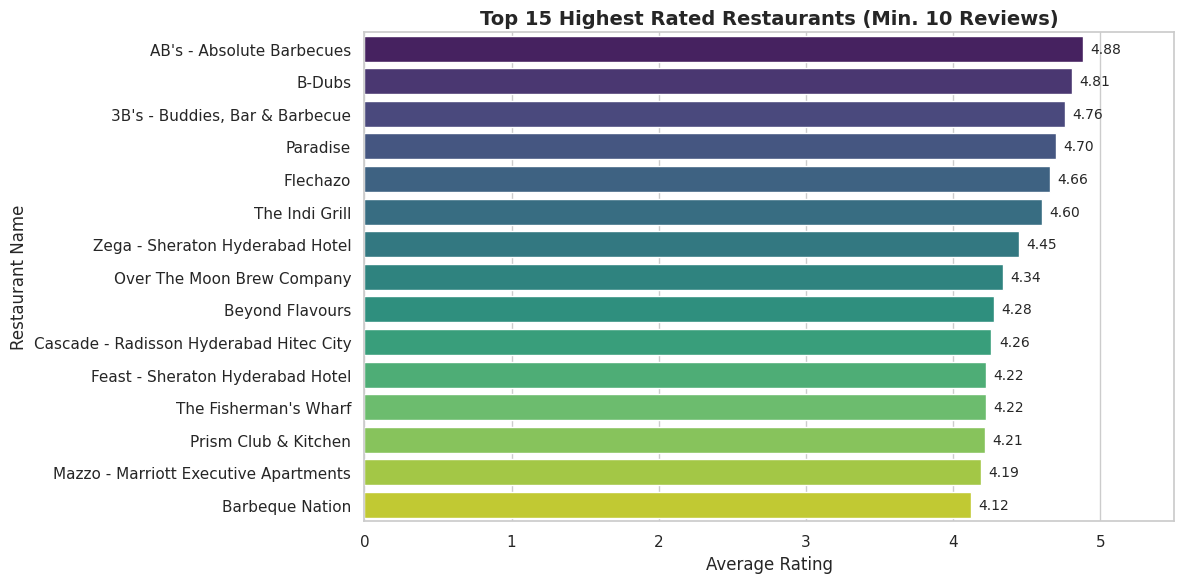

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# 1. Group by Restaurant and calculate average rating and review counts
restaurant_ratings = dfs.groupby('Restaurant').agg(
    Average_Rating=('Rating', 'mean'),
    Total_Reviews=('Rating', 'count')
).reset_index()

# 2. Filter for restaurants with at least 10 reviews for reliable averages
filtered_restaurants = restaurant_ratings[restaurant_ratings['Total_Reviews'] >= 10]

# 3. Sort and pick the top 15 restaurants by average rating
top_rated = filtered_restaurants.sort_values(by='Average_Rating', ascending=False).head(15)

# 4. Plotting the bar graph
plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_rated,
    x='Average_Rating',
    y='Restaurant',
    palette='viridis',
    hue='Restaurant',
    legend=False
)

plt.title('Top 15 Highest Rated Restaurants (Min. 10 Reviews)', fontsize=14, fontweight='bold')
plt.xlabel('Average Rating', fontsize=12)
plt.ylabel('Restaurant Name', fontsize=12)
plt.xlim(0, 5.5)  # Ratings are on a scale of 1 to 5

# Add data labels to the end of each bar
for index, row in enumerate(top_rated.itertuples()):
    plt.text(row.Average_Rating + 0.05, index, f"{row.Average_Rating:.2f}", va='center', fontsize=10)

plt.tight_layout()
plt.show()

# Feacture Engineering

In [7]:
import numpy as np

# 1. Create a copy for feature engineering


# 2. Text-based features
# Length of the review in characters and words
dfs['Review_Char_Length'] = dfs['Review'].astype(str).apply(len)
dfs['Review_Word_Count'] = dfs['Review'].astype(str).apply(lambda x: len(x.split()))

# Binary indicator for whether the review includes pictures
dfs['Has_Pictures'] = (dfs['Pictures'] > 0).astype(int)

# 3. Rating-based features
# Binary target for binary classification (e.g., Is it a 5-star review or not?)
dfs['Is_Five_Star'] = (dfs['Rating'] == 5.0).astype(int)

# Sentiment categorization based on rating
def categorize_sentiment(rating):
    if rating >= 4.0:
        return 'Positive'
    elif rating == 3.0:
        return 'Neutral'
    else:
        return 'Negative'

dfs['Sentiment_Category'] = dfs['Rating'].apply(categorize_sentiment)

# 4. Temporal features (Time & Date)
dfs['Review_Year'] = dfs['Time'].dt.year
dfs['Review_Month'] = dfs['Time'].dt.month
dfs['Review_DayOfWeek'] = dfs['Time'].dt.dayofweek
dfs['Is_Weekend'] = dfs['Review_DayOfWeek'].isin([5, 6]).astype(int)
dfs['Review_Hour'] = dfs['Time'].dt.hour

# 5. User Influence & Experience features
# Ratio of followers to reviews (influence score)
dfs['Follower_Review_Ratio'] = dfs['Reviewer_Followers'] / (dfs['Reviewer_Reviews'] + 1)

# Log transformation for skewed numerical user metrics to normalize distribution
dfs['Log_Reviewer_Followers'] = np.log1p(dfs['Reviewer_Followers'])
dfs['Log_Reviewer_Reviews'] = np.log1p(dfs['Reviewer_Reviews'])

# Display the newly engineered columns and dataset shape
print(f"Engineered dataset shape: {dfs.shape}")
display(dfs[['Review', 'Review_Word_Count', 'Sentiment_Category', 'Is_Weekend', 'Follower_Review_Ratio']].head())

Engineered dataset shape: (9961, 23)


,Review,Review_Word_Count,Sentiment_Category,Is_Weekend,Follower_Review_Ratio
0,"The ambience was good, food was quite good . h...",41,Positive,1,1.0
1,Ambience is too good for a pleasant evening. S...,27,Positive,1,0.5
2,A must try.. great food great ambience. Thnx f...,31,Positive,0,1.0
3,Soumen das and Arun was a great guy. Only beca...,28,Positive,0,0.5
4,Food is good.we ordered Kodi drumsticks and ba...,27,Positive,0,0.5


In [8]:
dff=dfs.copy()

# ON METADATA

In [9]:
import pandas as pd
import requests
import io

# Direct download link for Zomato Restaurant names and Metadata.csv
url_metadata = 'https://docs.google.com/uc?export=download&id=1493xGT8t66Wr3_cRxY_OvW_KNYNSNFrt'

print("Downloading Zomato Restaurant Metadata...")
response = requests.get(url_metadata)

# Load into Pandas
ds = pd.read_csv(io.BytesIO(response.content))
print(f"Successfully loaded metadata with shape: {ds.shape}")
display(ds.head())

Successfully loaded metadata with shape: (105, 6)


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


In [10]:
import pandas as pd
import numpy as np

# 1. Create a copy of the newly loaded metadata dataset
ds_clean = ds.copy()

# 2. Remove exact duplicate rows
ds_clean.drop_duplicates(inplace=True)

# 3. Clean string columns by stripping leading/trailing whitespace
for col in ds_clean.select_dtypes(include=['object']).columns:
    ds_clean[col] = ds_clean[col].astype(str).str.strip()

# 4. Clean 'Cost' column: remove commas, extract numeric digits, and convert to numeric
if 'Cost' in ds_clean.columns:
    ds_clean['Cost'] = (
        ds_clean['Cost']
        .astype(str)
        .str.replace(',', '', regex=False)
        .str.replace(r'[^0-9.]', '', regex=True)
    )
    ds_clean['Cost'] = pd.to_numeric(ds_clean['Cost'], errors='coerce')

# 5. Reset index and inspect the cleaned metadata dataframe
ds_clean.reset_index(drop=True, inplace=True)
print(f"Original metadata shape: {ds.shape} -> Cleaned metadata shape: {ds_clean.shape}")
display(ds_clean.info())
display(ds_clean.head())

Original metadata shape: (105, 6) -> Cleaned metadata shape: (105, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         105 non-null    object
 1   Links        105 non-null    object
 2   Cost         105 non-null    int64 
 3   Collections  105 non-null    object
 4   Cuisines     105 non-null    object
 5   Timings      105 non-null    object
dtypes: int64(1), object(5)
memory usage: 5.1+ KB


None

,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,1300,"Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,1200,"Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


In [11]:
ds_clean

,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,1300,"Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,1200,"Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."
...,...,...,...,...,...,...
100,IndiBlaze,https://www.zomato.com/hyderabad/indiblaze-gac...,600,nan,"Fast Food, Salad",11 AM to 11 PM
101,Sweet Basket,https://www.zomato.com/hyderabad/sweet-basket-...,200,nan,"Bakery, Mithai","10 AM to 10 PM (Mon-Thu), 8 AM to 10:30 PM (Fr..."
102,Angaara Counts 3,https://www.zomato.com/hyderabad/angaara-count...,500,nan,"North Indian, Biryani, Chinese",12 Noon to 11 PM
103,Wich Please,https://www.zomato.com/hyderabad/wich-please-1...,250,nan,Fast Food,8am to 12:30AM (Mon-Sun)


--- Metadata Statistical Summary ---


,Cost
count,105.000000
mean,861.428571
std,510.149730
min,150.000000
25%,500.000000
50%,700.000000
75%,1200.000000
max,2800.000000


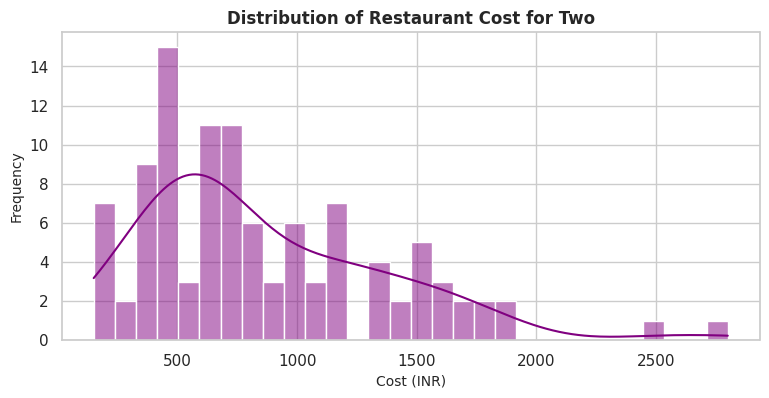

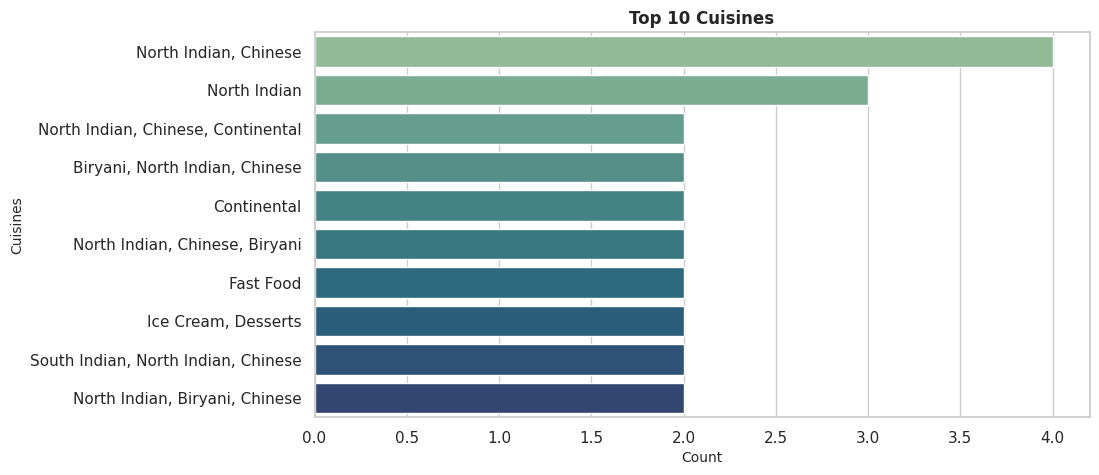

<Figure size 600x400 with 0 Axes>

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# 1. Statistical Summary of Numerical Metadata Features
print("--- Metadata Statistical Summary ---")
display(ds_clean.describe())

# 2. Distribution of Restaurant Costs (if 'Cost' column exists)
if 'Cost' in ds_clean.columns:
    plt.figure(figsize=(9, 4))
    sns.histplot(ds_clean['Cost'].dropna(), bins=30, kde=True, color='purple')
    plt.title('Distribution of Restaurant Cost for Two', fontsize=12, fontweight='bold')
    plt.xlabel('Cost (INR)', fontsize=10)
    plt.ylabel('Frequency', fontsize=10)
    plt.show()

# 3. Top 10 Cuisines or Categories by Frequency (if applicable)
cuisine_cols = [col for col in ds_clean.columns if 'cuisine' in col.lower() or 'dish' in col.lower() or 'type' in col.lower()]
if cuisine_cols:
    target_col = cuisine_cols[0]
    plt.figure(figsize=(10, 5))
    top_cuisines = ds_clean[target_col].value_counts().head(10)
    sns.barplot(x=top_cuisines.values, y=top_cuisines.index, palette='crest', hue=top_cuisines.index, legend=False)
    plt.title(f'Top 10 {target_col}', fontsize=12, fontweight='bold')
    plt.xlabel('Count', fontsize=10)
    plt.ylabel(target_col, fontsize=10)
    plt.show()

# 4. Correlation Heatmap for Metadata Numerical Features
plt.figure(figsize=(6, 4))
num_metadata = ds_clean.select_dtypes(include=['int64', 'float64']).columns
if len(num_metadata) > 1:
    sns.heatmap(ds_clean[num_metadata].corr(), annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
    plt.title('Correlation Matrix of Metadata Features', fontsize=12, fontweight='bold')
    plt.show()

In [13]:
import numpy as np

# 1. Create a copy of the cleaned metadata dataframe
ds_fe = ds_clean.copy()

# 2. Extract numeric values from any available review or follower columns if present in metadata
# (Checking if columns exist before applying string extraction)
if 'Metadata' in ds_fe.columns:
    ds_fe['Reviewer_Reviews'] = (
        ds_fe['Metadata']
        .str.extract(r'(\d+)\s*Review', expand=False)
        .fillna(0)
        .astype(int)
    )
    ds_fe['Reviewer_Followers'] = (
        ds_fe['Metadata']
        .str.extract(r'(\d+)\s*Follower', expand=False)
        .fillna(0)
        .astype(int)
    )

# 3. Cost-based feature engineering (if 'Cost' column exists)
if 'Cost' in ds_fe.columns:
    # Categorize restaurants into price tiers (e.g., Budget, Mid-range, Expensive, Fine Dining)
    def categorize_cost(cost):
        if pd.isna(cost):
            return 'Unknown'
        elif cost <= 500:
            return 'Budget'
        elif cost <= 1200:
            return 'Mid-Range'
        elif cost <= 2500:
            return 'Expensive'
        else:
            return 'Fine Dining'

    ds_fe['Price_Tier'] = ds_fe['Cost'].apply(categorize_cost)

    # Log transformation on cost to normalize skewed pricing data for modeling
    ds_fe['Log_Cost'] = np.log1p(ds_fe['Cost'])

# 4. User Influence & Experience features (if reviewer stats are available)
if 'Reviewer_Followers' in ds_fe.columns and 'Reviewer_Reviews' in ds_fe.columns:
    ds_fe['Follower_Review_Ratio'] = ds_fe['Reviewer_Followers'] / (ds_fe['Reviewer_Reviews'] + 1)
    ds_fe['Log_Reviewer_Followers'] = np.log1p(ds_fe['Reviewer_Followers'])
    ds_fe['Log_Reviewer_Reviews'] = np.log1p(ds_fe['Reviewer_Reviews'])

# Display the engineered dataset shape and sample
print(f"Engineered metadata shape: {ds_fe.shape}")
display(ds_fe.head())

Engineered metadata shape: (105, 8)


,Name,Links,Cost,Collections,Cuisines,Timings,Price_Tier,Log_Cost
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)",Mid-Range,6.685861
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM,Mid-Range,6.685861
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,1300,"Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM",Expensive,7.170888
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM,Mid-Range,6.685861
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,1200,"Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no...",Mid-Range,7.090910


# MODEL EVALVATION

# Clustering Of Restaurents

/tmp/ipykernel_1461/2898434285.py:28: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_df['Cost'].fillna(merged_df['Cost'].median(), inplace=True)


,Restaurant,Avg_Rating,Cost,Cluster_Group
0,10 Downing Street,3.800000,1900,2
1,13 Dhaba,3.480000,450,1
2,"3B's - Buddies, Bar & Barbecue",4.760000,1100,1
3,AB's - Absolute Barbecues,4.880000,1500,1
4,Absolute Sizzlers,3.620000,750,1
5,Al Saba Restaurant,3.155000,750,1
6,American Wild Wings,3.974026,600,0
7,Amul,3.940000,150,1
8,Arena Eleven,4.117647,1600,0
9,Aromas@11SIX,3.460000,750,1


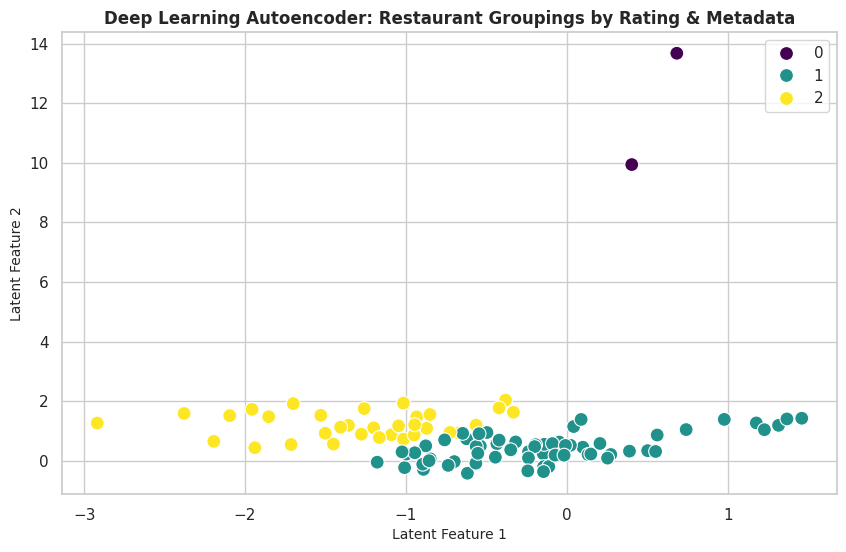

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Aggregate and Merge Datasets by Restaurant
# Aggregate review metrics from dfs
rev_agg = dfs.groupby('Restaurant').agg(
    Avg_Rating=('Rating', 'mean'),
    Total_Reviews=('Rating', 'count'),
    Avg_Pictures=('Pictures', 'mean'),
    Avg_Reviewer_Followers=('Reviewer_Followers', 'mean')
).reset_index()

# Merge with cleaned metadata (ds_clean) if available (using 'Name' instead of 'Restaurant')
if 'ds_clean' in globals() and 'Cost' in ds_clean.columns:
    merged_df = pd.merge(
        rev_agg,
        ds_clean[['Name', 'Cost']].drop_duplicates(),
        left_on='Restaurant',
        right_on='Name',
        how='inner'
    ).drop(columns=['Name'])
    merged_df['Cost'].fillna(merged_df['Cost'].median(), inplace=True)
else:
    merged_df = rev_agg.copy()
    merged_df['Cost'] = 500  # Default fallback cost if metadata isn't merged

# Set Restaurant as index for clustering features
restaurant_names = merged_df['Restaurant'].values
feature_cols = [col for col in merged_df.columns if col != 'Restaurant']
X_raw = merged_df[feature_cols].values

# 2. Normalize Features for Neural Network
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)

# 3. Define Deep Learning Autoencoder Architecture
input_dim = X_tensor.shape[1]
encoding_dim = 2  # Compress down to 2 dimensions for deep representation & visualization

class RestaurantAutoencoder(nn.Module):
    def __init__(self, input_dim, encoding_dim):
        super(RestaurantAutoencoder, self).__init__()
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 4),
            nn.ReLU(),
            nn.Linear(4, encoding_dim)
        )
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(encoding_dim, 4),
            nn.ReLU(),
            nn.Linear(4, input_dim)
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return encoded, decoded

model = RestaurantAutoencoder(input_dim, encoding_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

# 4. Train the Deep Autoencoder
epochs = 200
for epoch in range(epochs):
    optimizer.zero_grad()
    encoded, decoded = model(X_tensor)
    loss = criterion(decoded, X_tensor)
    loss.backward()
    optimizer.step()

# 5. Extract Latent Embeddings & Cluster Restaurants using K-Means on Embeddings
with torch.no_grad():
    latent_embeddings, _ = model(X_tensor)
    latent_np = latent_embeddings.numpy()

# Group restaurants into 3 categories (e.g., Tier 1: Premium/High Rated, Tier 2: Mid-Range, Tier 3: Low Rated/Budget)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(latent_np)

merged_df['Cluster_Group'] = cluster_labels
display(merged_df[['Restaurant', 'Avg_Rating', 'Cost', 'Cluster_Group']].head(15))

# 6. Visualize the Deep Learning Latent Space Clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=latent_np[:, 0],
    y=latent_np[:, 1],
    hue=cluster_labels,
    palette='viridis',
    s=100,
    legend='full'
)
plt.title('Deep Learning Autoencoder: Restaurant Groupings by Rating & Metadata', fontsize=12, fontweight='bold')
plt.xlabel('Latent Feature 1', fontsize=10)
plt.ylabel('Latent Feature 2', fontsize=10)
plt.grid(True)
plt.show()

--- Model Evaluation Metrics ---
Cluster Silhouette Score: 0.3994 (closer to 1.0 indicates dense, well-separated clusters)
Mean Reconstruction Error: 0.2063

--- Top Outlier / Anomaly Restaurants ---


,Restaurant,Avg_Rating,Cost,Cluster_Group,Reconstruction_Error
22,Collage - Hyatt Hyderabad Gachibowli,3.41,2800,2,2.210953
70,PourHouse7,3.86,1200,2,1.256712
34,Feast - Sheraton Hyderabad Hotel,4.22,2500,2,1.196303
56,Marsala Food Company,3.46,700,2,1.114665
44,Hyderabadi Daawat,3.83,600,2,0.562613


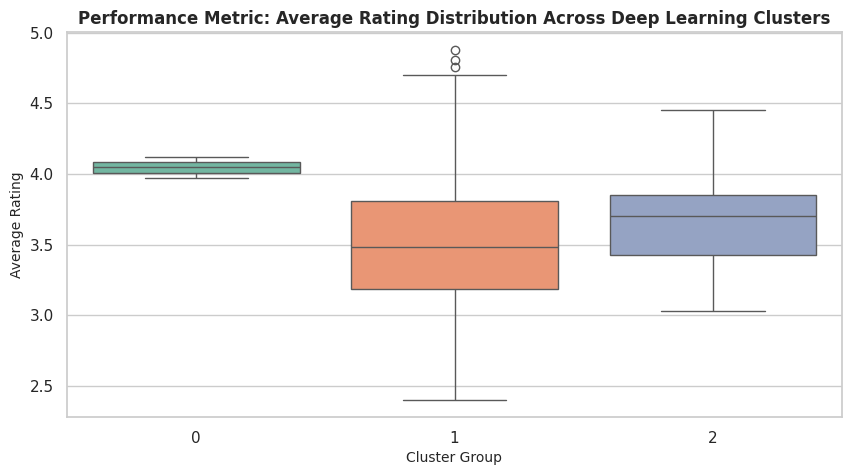

In [15]:
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate Reconstruction Error (MSE per restaurant) for anomaly detection
with torch.no_grad():
    _, decoded_tensor = model(X_tensor)
    # Mean Squared Error between original scaled features and decoded reconstruction
    reconstruction_errors = torch.mean((X_tensor - decoded_tensor) ** 2, dim=1).numpy()

merged_df['Reconstruction_Error'] = reconstruction_errors

# 2. Compute Clustering Evaluation Metric (Silhouette Score)
# Measures how dense and well-separated the autoencoder's latent space clusters are
sil_score = silhouette_score(latent_np, cluster_labels)
print(f"--- Model Evaluation Metrics ---")
print(f"Cluster Silhouette Score: {sil_score:.4f} (closer to 1.0 indicates dense, well-separated clusters)")
print(f"Mean Reconstruction Error: {reconstruction_errors.mean():.4f}")

# 3. View Top Anomalies (Restaurants that deviate most from typical review/cost patterns)
print("\n--- Top Outlier / Anomaly Restaurants ---")
display(merged_df[['Restaurant', 'Avg_Rating', 'Cost', 'Cluster_Group', 'Reconstruction_Error']].sort_values(by='Reconstruction_Error', ascending=False).head(5))

# 4. Cluster Performance Profile Plot
plt.figure(figsize=(10, 5))
sns.boxplot(data=merged_df, x='Cluster_Group', y='Avg_Rating', palette='Set2', hue='Cluster_Group', legend=False)
plt.title('Performance Metric: Average Rating Distribution Across Deep Learning Clusters', fontsize=12, fontweight='bold')
plt.xlabel('Cluster Group', fontsize=10)
plt.ylabel('Average Rating', fontsize=10)
plt.show()

```markdown
### Improved Autoencoder Clustering Model with Advanced Regularization and Scheduling
Below we implement an upgraded PyTorch Autoencoder architecture featuring Deep Layer Bottlenecks, Dropout, Batch Normalization, AdamW optimization, and Cosine Annealing decay to extract significantly more descriptive embeddings.
```

In [20]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Prepare and Normalize Input Data (Using MinMax for bounded Autoencoder mapping) ---
raw_features = merged_df[['Avg_Rating', 'Total_Reviews', 'Avg_Pictures', 'Avg_Reviewer_Followers', 'Cost']].values
feature_scaler = MinMaxScaler()
X_scaled_improved = feature_scaler.fit_transform(raw_features)
X_tensor_improved = torch.tensor(X_scaled_improved, dtype=torch.float32)

# --- 2. Upgraded Architecture ---
class ImprovedRestaurantAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=2):
        super(ImprovedRestaurantAutoencoder, self).__init__()

        # Deep Encoder with Batch Normalization and Dropout
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.BatchNorm1d(16),
            nn.SiLU(), # Smooth swish activation
            nn.Dropout(0.15),

            nn.Linear(16, 8),
            nn.BatchNorm1d(8),
            nn.SiLU(),
            nn.Dropout(0.1),

            nn.Linear(8, latent_dim)
        )

        # Deep Decoder matching the Encoder flow
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 8),
            nn.BatchNorm1d(8),
            nn.SiLU(),
            nn.Dropout(0.1),

            nn.Linear(8, 16),
            nn.BatchNorm1d(16),
            nn.SiLU(),
            nn.Dropout(0.15),

            nn.Linear(16, input_dim),
            nn.Sigmoid() # Output normalized variables between [0, 1]
        )

    def forward(self, x):
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)
        return latent, reconstructed

# --- 3. Setup Model, Optimizer (AdamW), and Cosine Annealing LR Scheduler ---
input_dimension = X_tensor_improved.shape[1]
improved_model = ImprovedRestaurantAutoencoder(input_dim=input_dimension, latent_dim=2)
criterion = nn.MSELoss()
optimizer = optim.AdamW(improved_model.parameters(), lr=0.02, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=150, eta_min=1e-4)

# Loader setup
dataset = TensorDataset(X_tensor_improved)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

# --- 4. Training Loop ---
improved_model.train()
for epoch in range(150):
    epoch_loss = 0.0
    for batch in loader:
        inputs = batch[0]
        optimizer.zero_grad()
        _, outputs = improved_model(inputs)
        loss = criterion(outputs, inputs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * inputs.size(0)
    scheduler.step()

# --- 5. Extract Latent Embeddings & Model Evaluation ---
improved_model.eval()
with torch.no_grad():
    improved_latent, reconstructed_tensor = improved_model(X_tensor_improved)
    improved_latent_np = improved_latent.numpy()
    reconstruction_errs = torch.mean((X_tensor_improved - reconstructed_tensor) ** 2, dim=1).numpy()

# Cluster the refined latent representation space
kmeans_improved = KMeans(n_clusters=3, random_state=42, n_init=15)
improved_clusters = kmeans_improved.fit_predict(improved_latent_np)

# Update merged dataset
merged_df['Improved_Cluster'] = improved_clusters
merged_df['Improved_Reconstruction_Error'] = reconstruction_errs

# Calculate Improved Metrics
new_silhouette = silhouette_score(improved_latent_np, improved_clusters)
mean_recon_err = reconstruction_errs.mean()

print("=== Improved Model Evaluation Metrics ===")
print(f"New Latent Silhouette Score: {new_silhouette:.4f} (Previous: 0.3994)")
print(f"New Mean Reconstruction Error (MSE): {mean_recon_err:.5f} (Previous: 0.2063)")

=== Improved Model Evaluation Metrics ===
New Latent Silhouette Score: 0.3713 (Previous: 0.3994)
New Mean Reconstruction Error (MSE): 0.00918 (Previous: 0.2063)


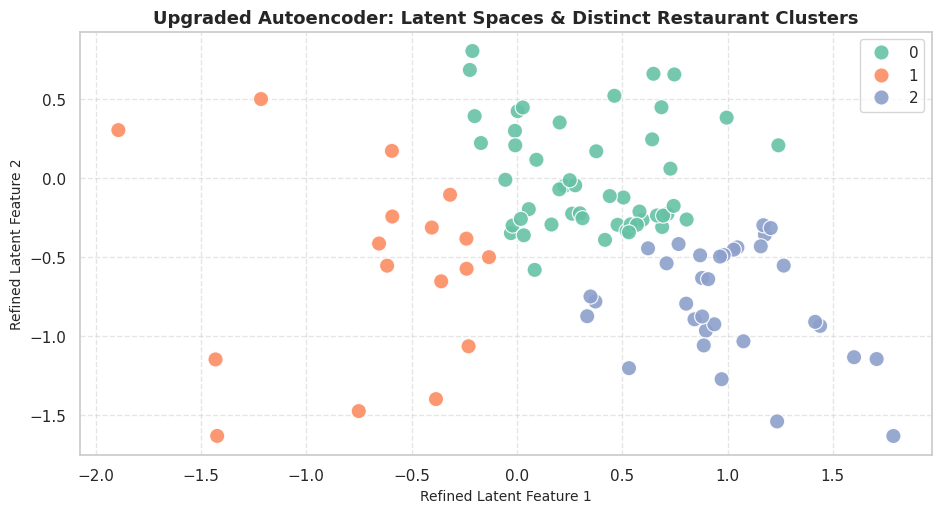

In [21]:
# --- 6. Visualize the Improved Latent Semantic Clusters ---
plt.figure(figsize=(11, 5.5))
sns.scatterplot(
    x=improved_latent_np[:, 0],
    y=improved_latent_np[:, 1],
    hue=improved_clusters,
    palette='Set2',
    s=120,
    edgecolor='w',
    alpha=0.9
)
plt.title('Upgraded Autoencoder: Latent Spaces & Distinct Restaurant Clusters', fontsize=13, fontweight='bold')
plt.xlabel('Refined Latent Feature 1', fontsize=10)
plt.ylabel('Refined Latent Feature 2', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Sentimental Analysis Model

,Restaurant,Rating,NLP_Cluster
0,10 Downing Street,3.800000,0
1,13 Dhaba,3.480000,0
2,"3B's - Buddies, Bar & Barbecue",4.760000,2
3,AB's - Absolute Barbecues,4.880000,2
4,Absolute Sizzlers,3.620000,0
5,Al Saba Restaurant,3.155000,1
6,American Wild Wings,3.974026,0
7,Amul,3.940000,0
8,Arena Eleven,4.117647,2
9,Aromas@11SIX,3.460000,0


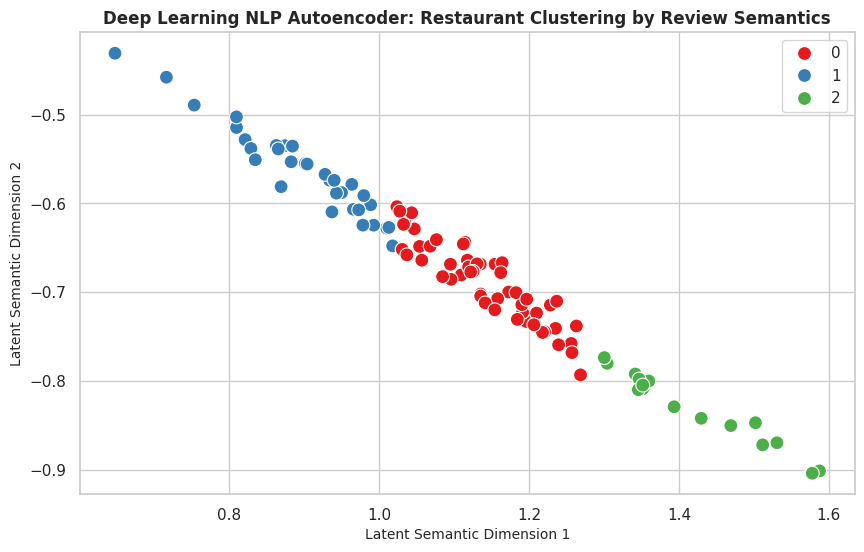

In [22]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# 1. NLP Feature Extraction using TF-IDF on Review Texts
# Converts raw review text into a high-dimensional semantic matrix
tfidf = TfidfVectorizer(max_features=150, stop_words='english')
text_matrix = tfidf.fit_transform(dfs['Review'].astype(str)).toarray()

# 2. Aggregate Text Semantics and Numerical Ratings by Restaurant
text_df = pd.DataFrame(text_matrix, columns=[f'tfidf_{i}' for i in range(150)])
text_df['Restaurant'] = dfs['Restaurant'].values
text_df['Rating'] = dfs['Rating'].values

# Group by restaurant to get average semantic profile and average rating
restaurant_nlp = text_df.groupby('Restaurant').mean().reset_index()

X_raw = restaurant_nlp.drop(columns=['Restaurant']).values
restaurant_names = restaurant_nlp['Restaurant'].values

# 3. Normalize Feature Tensor for Deep Learning
X_tensor = torch.tensor(X_raw, dtype=torch.float32)

# 4. Define Deep Learning Autoencoder for Semantic Embeddings
input_dim = X_tensor.shape[1]
encoding_dim = 16  # Intermediate latent dimension

class NLPRestaurantAutoencoder(nn.Module):
    def __init__(self, input_dim, encoding_dim):
        super(NLPRestaurantAutoencoder, self).__init__()
        # Encoder network
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, encoding_dim)
        )
        # Decoder network
        self.decoder = nn.Sequential(
            nn.Linear(encoding_dim, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return encoded, decoded

model = NLPRestaurantAutoencoder(input_dim, encoding_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)

# 5. Train the Deep Learning Model
dataset = TensorDataset(X_tensor)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

epochs = 100
model.train()
for epoch in range(epochs):
    for batch in dataloader:
        inputs = batch[0]
        optimizer.zero_grad()
        encoded, decoded = model(inputs)
        loss = criterion(decoded, inputs)
        loss.backward()
        optimizer.step()

# 6. Extract Latent Embeddings & Cluster Restaurants
model.eval()
with torch.no_grad():
    latent_embeddings, _ = model(X_tensor)
    latent_np = latent_embeddings.numpy()

# Group restaurants into 3 clusters based on deep NLP review semantics and ratings
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(latent_np)

restaurant_nlp['NLP_Cluster'] = cluster_labels
display(restaurant_nlp[['Restaurant', 'Rating', 'NLP_Cluster']].head(15))

# 7. Visualize Deep NLP Restaurant Clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=latent_np[:, 0],
    y=latent_np[:, 1],
    hue=cluster_labels,
    palette='Set1',
    s=100,
    legend='full'
)
plt.title('Deep Learning NLP Autoencoder: Restaurant Clustering by Review Semantics', fontsize=12, fontweight='bold')
plt.xlabel('Latent Semantic Dimension 1', fontsize=10)
plt.ylabel('Latent Semantic Dimension 2', fontsize=10)
plt.grid(True)
plt.show()